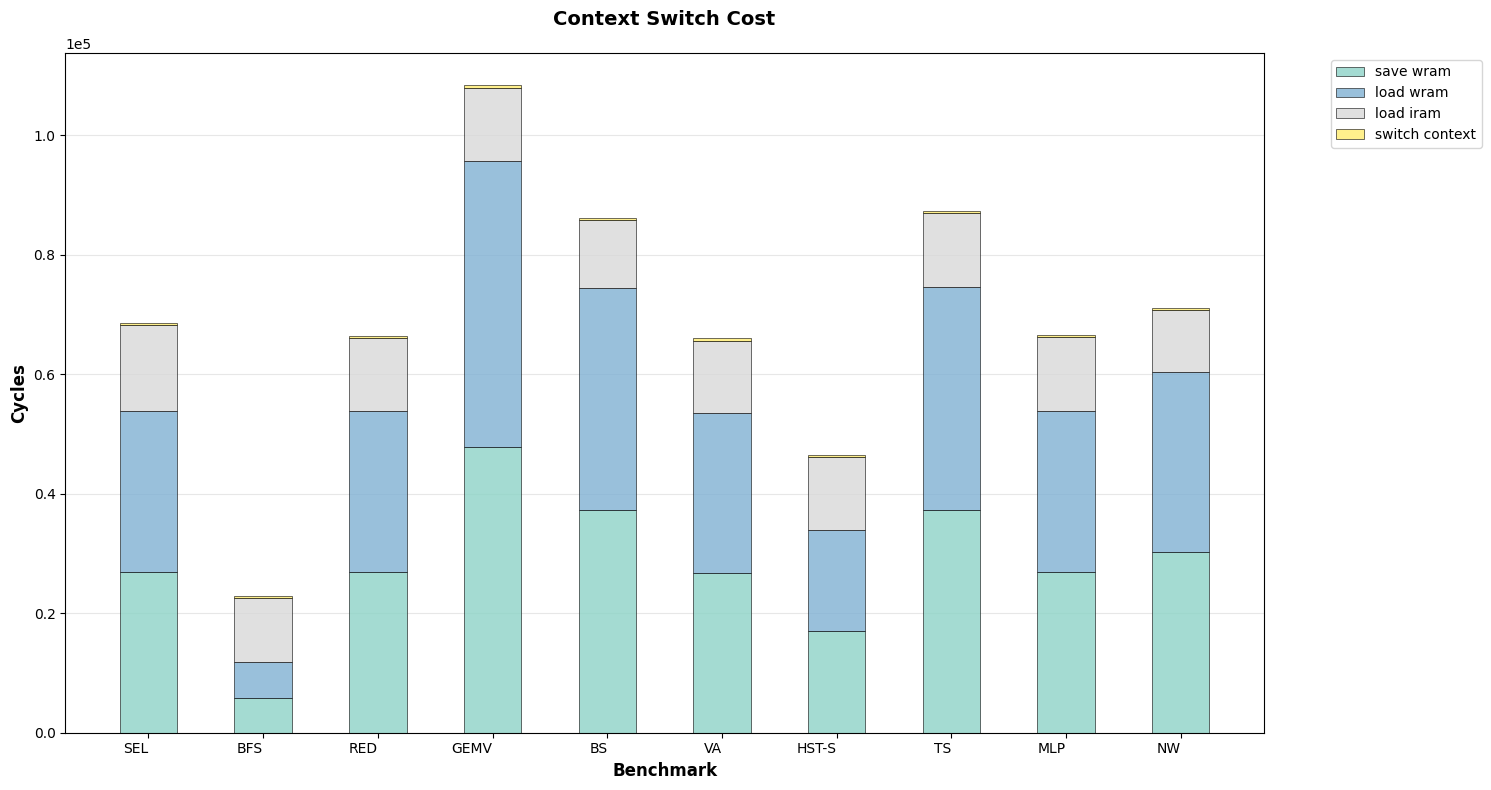

In [1]:
#!/usr/bin/env python3
# -*- coding: utf-8 -*-

import os
import re
import glob
import pandas as pd
from pathlib import Path
import argparse
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.patches as mpatches

class DebugTimeAnalyzer:
    def __init__(self):
        self.debug_pattern = re.compile(r'break point (\d+) happen in cycle:\s*(\d+)')
        self.time_pattern = re.compile(r'\*+time:(\d+)\*+')
        
    def parse_single_file(self, file_path):
        """Parse single track file"""
        debug_points = {}
        current_time = None
        
        try:
            with open(file_path, 'r', encoding='utf-8', errors='ignore') as f:
                for line in f:
                    line = line.strip()
                    
                    # Match timestamp
                    time_match = self.time_pattern.search(line)
                    if time_match:
                        current_time = int(time_match.group(1))
                        continue
                    
                    # Match break point
                    debug_match = self.debug_pattern.search(line)
                    if debug_match:
                        point_id = int(debug_match.group(1))
                        cycle = int(debug_match.group(2))
                        debug_points[point_id] = {
                            'cycle': cycle,
                            'time': current_time
                        }
                        
        except Exception as e:
            print(f"Error parsing file {file_path}: {e}")
            return None
            
        return debug_points
    
    def calculate_time_differences(self, debug_points):
        """Calculate time differences between adjacent debug points"""
        time_diffs = {}
        
        # Get all debug point IDs and sort them
        point_ids = sorted(debug_points.keys())
        
        # Calculate differences between adjacent points (debug1-debug0, debug3-debug2, debug5-debug4, ...)
        for i in range(0, len(point_ids)-1, 2):
            if i+1 < len(point_ids):
                point_a = point_ids[i]      # debug0, debug2, debug4, ...
                point_b = point_ids[i+1]    # debug1, debug3, debug5, ...
                
                if point_a in debug_points and point_b in debug_points:
                    cycle_a = debug_points[point_a]['cycle']
                    cycle_b = debug_points[point_b]['cycle']
                    time_diff = cycle_b - cycle_a
                    
                    # Map index to operation name
                    if i == 0:
                        name = "save wram"
                    elif i == 2:
                        name = "load wram"
                    elif i == 4:
                        name = "load iram"
                    elif i == 6:
                        name = "switch context"
                    else:
                        assert False, "Unexpected point index"
                    
                    time_diffs[name] = {
                        'point_a': point_a,
                        'point_b': point_b,
                        'cycle_a': cycle_a,
                        'cycle_b': cycle_b,
                        'time_diff': time_diff,
                        'time_a': debug_points[point_a].get('time'),
                        'time_b': debug_points[point_b].get('time')
                    }
        
        return time_diffs
    
    def process_multiple_files(self, file_patterns):
        """Process multiple track files"""
        all_results = {}
        
        # Collect all matching files
        all_files = []
        for pattern in file_patterns:
            files = glob.glob(pattern)
            all_files.extend(files)
        
        if not all_files:
            return None
        
        for file_path in all_files:
            # Parse file
            debug_points = self.parse_single_file(file_path)
            if debug_points is None or not debug_points:
                continue
            
            # Calculate time differences
            time_diffs = self.calculate_time_differences(debug_points)
            
            # Store results
            file_name = Path(file_path).name
            all_results[file_name] = {
                'debug_points': debug_points,
                'time_diffs': time_diffs,
                'file_path': file_path
            }
        
        return all_results
    
    def clean_filename(self, filename):
        """Clean filename by removing _output suffix etc."""
        # Remove file extension
        name = Path(filename).stem
        
        # Remove _output suffix
        if name.endswith('_output'):
            name = name[:-7]
        
        return name
    
    def create_bar_chart(self, results, save_path="debug_time_chart.png", show_plot=True):
        """Create bar chart showing debug time differences"""
        if not results:
            return None
        
        # Set font for better compatibility
        plt.rcParams['font.sans-serif'] = ['Arial', 'DejaVu Sans']
        plt.rcParams['axes.unicode_minus'] = False
        
        # Prepare data
        file_names = []
        clean_names = []
        time_diff_data = {}
        
        # Collect all possible time difference types
        all_diff_types = set()
        for file_name, data in results.items():
            time_diffs = data['time_diffs']
            all_diff_types.update(time_diffs.keys())
        
        # Sort by operation order
        operation_order = ["save wram", "load wram", "load iram", "switch context"]
        sorted_diff_types = [op for op in operation_order if op in all_diff_types]
        
        # Prepare data lists for each time difference type
        for diff_type in sorted_diff_types:
            time_diff_data[diff_type] = []
        
        # Collect data for each file
        for file_name, data in results.items():
            file_names.append(file_name)
            clean_names.append(self.clean_filename(file_name))
            time_diffs = data['time_diffs']
            
            # Add values for each time difference type, 0 if not present
            for diff_type in sorted_diff_types:
                if diff_type in time_diffs:
                    time_diff_data[diff_type].append(time_diffs[diff_type]['time_diff'])
                else:
                    time_diff_data[diff_type].append(0)
        
        # Create figure
        fig, ax = plt.subplots(figsize=(max(12, len(file_names) * 1.5), 8))
        
        # Set colors
        colors = plt.cm.Set3(np.linspace(0, 1, len(sorted_diff_types)))
        
        # Create stacked bar chart
        bottom = np.zeros(len(file_names))
        bars = []
        
        for i, diff_type in enumerate(sorted_diff_types):
            values = time_diff_data[diff_type]
            bar = ax.bar(clean_names, values, bottom=bottom, 
                        label=diff_type, color=colors[i], 
                        alpha=0.8, edgecolor='black', linewidth=0.5, width=0.5)
            bars.append(bar)
            bottom += np.array(values)
        
        # Set chart properties
        ax.set_xlabel('Benchmark', fontsize=12, fontweight='bold')
        ax.set_ylabel('Cycles', fontsize=12, fontweight='bold')
        ax.set_title('Context Switch Cost', 
                    fontsize=14, fontweight='bold', pad=20)
        
        # Rotate x-axis labels to prevent overlap
        plt.xticks(rotation=0, ha='right')
        
        # Set y-axis format
        ax.ticklabel_format(style='scientific', axis='y', scilimits=(0,0))
        
        # Add legend
        ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=10)
        
        # Add grid
        ax.grid(True, alpha=0.3, axis='y')
        ax.set_axisbelow(True)
        
        # Adjust layout
        plt.tight_layout()
        
        # Save chart
        if save_path:
            plt.savefig(save_path, dpi=300, bbox_inches='tight', facecolor='white')
        
        # Show chart
        if show_plot:
            plt.show()
        
        return fig, ax

def main(file_patterns=None, create_charts=True):
    """
    Main function - suitable for Jupyter notebook calls
    
    Parameters:
    - file_patterns: list of file paths or wildcard patterns
    - create_charts: whether to create charts
    """
    analyzer = DebugTimeAnalyzer()
    
    # Use default patterns if none specified
    if file_patterns is None:
        file_patterns = ["*.track", "*.log", "*.txt"]
    
    # Process files
    results = analyzer.process_multiple_files(file_patterns)
    
    if results and create_charts and len(results) > 0:
        analyzer.create_bar_chart(results, "context_switch.png", True)
    
    return results

def analyze_debug_files(file_patterns, create_charts=True):
    """
    Convenience function - direct call to analysis functionality
    
    Usage examples:
    # Analyze single file and generate chart
    results = analyze_debug_files(["track1.log"])
    
    # Analyze multiple files without generating charts
    results = analyze_debug_files(["*.log"], create_charts=False)
    
    Parameters:
    - file_patterns: list of file paths or wildcard patterns
    - create_charts: whether to create charts
    """
    return main(file_patterns, create_charts)

def parse_command_line():
    """Command line argument parsing - only used in command line mode"""
    parser = argparse.ArgumentParser(description='Analyze debug time differences in track files')
    parser.add_argument('files', nargs='+', help='Track file paths or wildcard patterns')
    
    args = parser.parse_args()
    main(args.files)

if __name__ == "__main__":
    try:
        # If in Jupyter environment
        main()
    except NameError:
        # Not in Jupyter environment, use command line parsing
        import sys
        if len(sys.argv) == 1:
            # No command line arguments, use default mode
            main()
        else:
            # Has command line arguments, parse and execute
            parse_command_line()